Research Assignment - dsc 212

Modularity on the Karate Club Graph

Tasks
1. Implement recursive spectral modularity partitioning to detect multiple communities.
2. Visualize the graph after each split, coloring communities differently.
3. After each split, use networkx functions to compute:
• degree centrality,
• betweenness centrality,
• closeness centrality,
• clustering.
4. Plot the evolution of each metric across iterations for every node.
5. Write a short discussion: which nodes consistently remain central across splits, and how
community structure influences these metrics.

Step1: Import libraries and import the zachary's karate club's graph and plot the graph

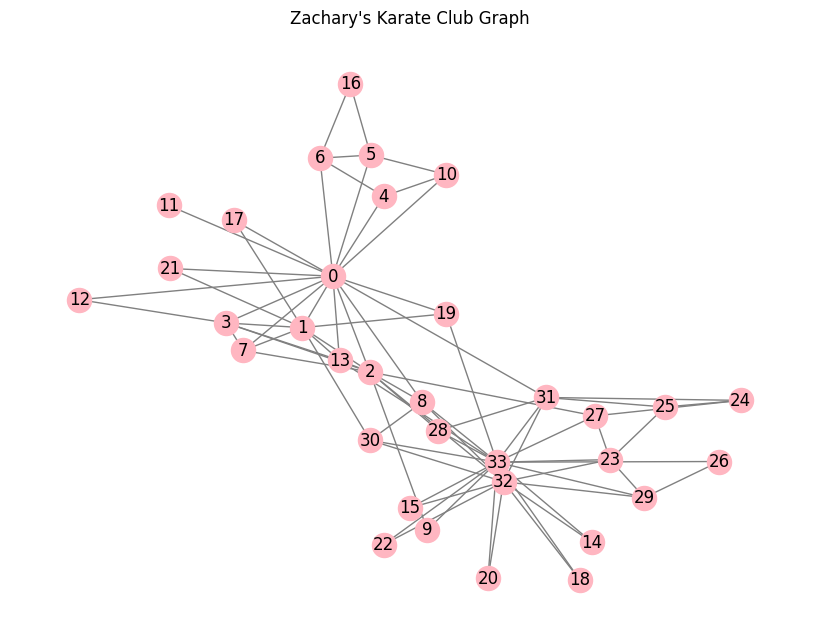

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

G = nx.karate_club_graph()
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color='lightpink', edge_color='gray')
plt.title("Zachary's Karate Club Graph")
plt.show()



Step 2: Make the adjacency matrix and modularity matrix from graph



In [2]:
def modularity_matrix(G):
    """
    Compute modularity matrix B = A - (k k^T)/(2m) for the given subgraph G.
    """
    # Convert the given G (subgraph or full graph) to adjacency matrix
    A = nx.to_numpy_array(G)
    k = A.sum(axis=1)
    m = A.sum() / 2
    B = A - np.outer(k, k) / (2 * m)
    return B, A, k, m


Step 3: Define Modularity score

In [3]:
def modularity_score(G, s):
    B, A, k, m = modularity_matrix(G)
    return float((1 / (4 * m)) * s.T @ B @ s)



Step 4: Define a function to compute eigen values and eigen vectors

In [4]:
def eigen(G):
  B=modularity_matrix(G)[0]
  values,vectors=np.linalg.eigh(B)
  i=np.argmax(values)
  lambda1=values[i]
  v1=vectors[:,i]
  return lambda1,v1

Step 5: Define a function to visualize splitting after every iteration


In [5]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import networkx as nx

def visualize(G, communities, pos=None, title="Final Communities"):
    if pos is None:
        pos = nx.spring_layout(G, seed=42)

    # Generate enough distinct colors
    colors = list(mcolors.TABLEAU_COLORS.values()) + list(mcolors.CSS4_COLORS.values())

    plt.figure(figsize=(8, 6))
    for i, community in enumerate(communities):
        nx.draw_networkx_nodes(
            G, pos,
            nodelist=community,
            node_color=colors[i % len(colors)],
            label=f"Community {i+1}",
            node_size=400,
            alpha=0.9
        )
    nx.draw_networkx_edges(G, pos, alpha=0.5)
    nx.draw_networkx_labels(G, pos, font_color="black", font_size=9)
    plt.title(title)
    plt.legend()
    plt.axis("off")
    plt.show()


Step 6:We use the recursive splitting

In [6]:
def recursive_spectral_modularity(G, pos=None, depth=0, max_depth=3, communities_so_far=None, min_community_size=8):

    if communities_so_far is None:
        communities_so_far = [list(G.nodes())]
        if pos is None:
            pos = nx.spring_layout(G, seed=42)
        plt.figure(figsize=(8, 6))
        nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray")
        plt.title("Initial Graph")
        plt.show()

    if depth > max_depth:
        print(f"Reached max depth {max_depth}")
        return communities_so_far


    A_orig = nx.to_numpy_array(G)
    m_orig = A_orig.sum() / 2

    new_communities = []
    split_occurred = False

    for comm in communities_so_far:
        subG = G.subgraph(comm)


        if subG.number_of_nodes() < min_community_size:
            new_communities.append(comm)
            print(f"  Community too small ({len(comm)} nodes), keeping intact")
            continue


        B, A, k, m = modularity_matrix(subG)

        try:
            lambda1, u1 = eigen(subG)
        except np.linalg.LinAlgError:
            new_communities.append(comm)
            print(f"  Eigenvalue computation failed, keeping community intact")
            continue

        print(f"  Community size: {len(comm)}, λ₁ = {lambda1:.6f}")


        if lambda1 <= 0.005:  # stricter threshold
            new_communities.append(comm)
            print(f"    → λ₁ too small, NOT splitting")
            continue

        # Create the split
        s = np.where(u1 > 0, 1, -1)
        nodes = np.array(list(subG.nodes()))

        C_plus = nodes[s == 1].tolist()
        C_minus = nodes[s == -1].tolist()


        min_size = min(len(C_plus), len(C_minus))
        if min_size < 5:
            new_communities.append(comm)
            print(f"    → Split too unbalanced ({len(C_plus)} vs {len(C_minus)}), NOT splitting")
            continue

        delta_Q = (1 / (4 * m_orig)) * s.T @ B @ s

        print(f"    → ΔQ = {delta_Q:.6f}, split sizes: {len(C_plus)} and {len(C_minus)}")


        if delta_Q <= 0.02:
            new_communities.append(comm)
            print(f"    → ΔQ too small, NOT splitting")
            continue

        # Accept the split
        new_communities.extend([C_plus, C_minus])
        split_occurred = True
        print(f"    → ✓ SPLITTING into {len(C_plus)} and {len(C_minus)} nodes")

    if split_occurred:
        print(f"\nIteration {depth + 1}: Found {len(new_communities)} communities\n")
        visualize(G, new_communities, pos,
                  title=f"Iteration {depth + 1}: {len(new_communities)} communities")
        return recursive_spectral_modularity(G, pos=pos, depth=depth + 1,
                                             max_depth=max_depth,
                                             communities_so_far=new_communities,
                                             min_community_size=min_community_size)
    else:
        print(f"\nNo more beneficial splits. Final: {len(communities_so_far)} communities\n")
        return communities_so_far

Step 7:Define the metrics

In [7]:
def compute_metrics(G, communities):
    metrics = {
        'degree': nx.degree_centrality(G),
        'betweenness': nx.betweenness_centrality(G),
        'closeness': nx.closeness_centrality(G),
        'clustering': nx.clustering(G)
    }
    return metrics


Step 8:Track the metrics along the splitting

In [8]:
def track_metrics_evolution(G, pos=None, max_depth=3, min_community_size=8):
    metrics_evolution = []
    communities_so_far = [list(G.nodes())]

    A_orig = nx.to_numpy_array(G)
    m_orig = A_orig.sum() / 2

    for depth in range(max_depth + 1):
        metrics = compute_metrics(G, communities_so_far)
        metrics_evolution.append(metrics)

        new_communities = []
        split_occurred = False

        for comm in communities_so_far:
            subG = G.subgraph(comm)
            if subG.number_of_nodes() < min_community_size:
                new_communities.append(comm)
                continue

            try:
                B, A, k, m = modularity_matrix(subG)
                lambda1, u1 = eigen(subG)

                if lambda1 <= 0.005:
                    new_communities.append(comm)
                    continue

                s = np.where(u1 > 0, 1, -1)
                nodes = np.array(list(subG.nodes()))
                C_plus = nodes[s == 1].tolist()
                C_minus = nodes[s == -1].tolist()

                min_size = min(len(C_plus), len(C_minus))
                if min_size < 5:
                    new_communities.append(comm)
                    continue

                delta_Q = (1 / (4 * m_orig)) * s.T @ B @ s

                if delta_Q > 0.02:
                    new_communities.extend([C_plus, C_minus])
                    split_occurred = True
                else:
                    new_communities.append(comm)
            except:
                new_communities.append(comm)

        if not split_occurred:
            break

        communities_so_far = new_communities

    return metrics_evolution

Step 9:Plot our metricss

In [9]:
def plot_metrics_evolution(metrics_evolution, selected_nodes=[0, 33, 1, 2]):
    """
    Plot the evolution of each metric across iterations for selected nodes.
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    metric_names = ['degree', 'betweenness', 'closeness', 'clustering']

    for idx, metric_name in enumerate(metric_names):
        ax = axes[idx // 2, idx % 2]

        for node in selected_nodes:
            values = [iteration[metric_name][node] for iteration in metrics_evolution]
            ax.plot(range(len(values)), values, marker='o', label=f'Node {node}')

        ax.set_xlabel('Iteration')
        ax.set_ylabel(metric_name.capitalize())
        ax.set_title(f'{metric_name.capitalize()} Centrality Evolution')
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

Step 10:Execute all the above functions to get our splitting

Starting Recursive Spectral Modularity Analysis


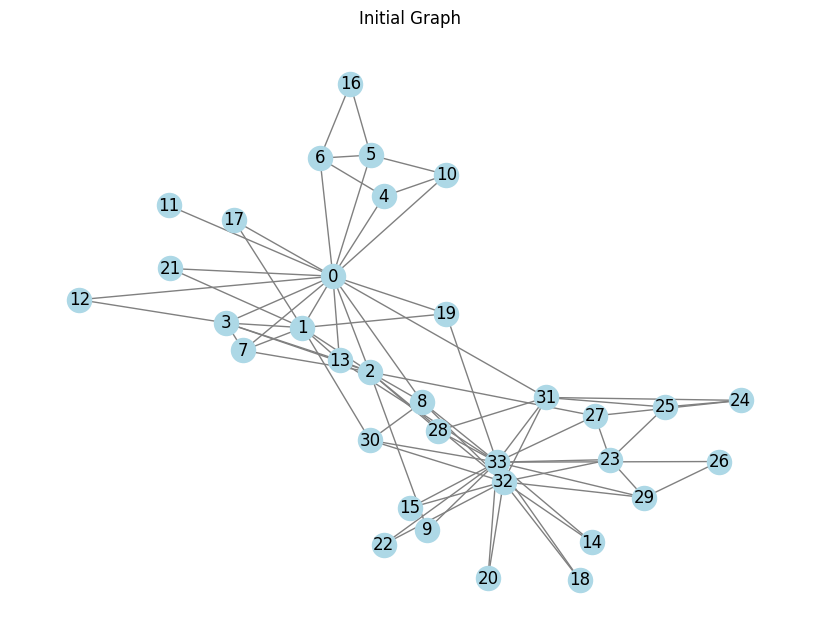

  Community size: 34, λ₁ = 17.108708
    → ΔQ = 0.403628, split sizes: 16 and 18
    → ✓ SPLITTING into 16 and 18 nodes

Iteration 1: Found 2 communities



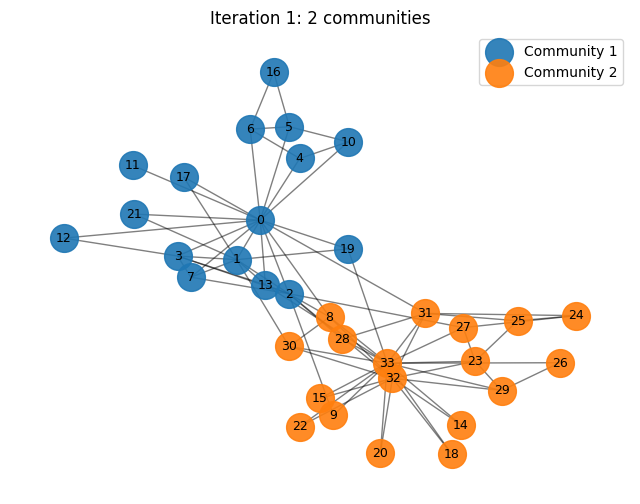

  Community size: 16, λ₁ = 10.312158
    → ΔQ = 0.108619, split sizes: 9 and 7
    → ✓ SPLITTING into 9 and 7 nodes
  Community size: 18, λ₁ = 7.876374
    → ΔQ = 0.102794, split sizes: 6 and 12
    → ✓ SPLITTING into 6 and 12 nodes

Iteration 2: Found 4 communities



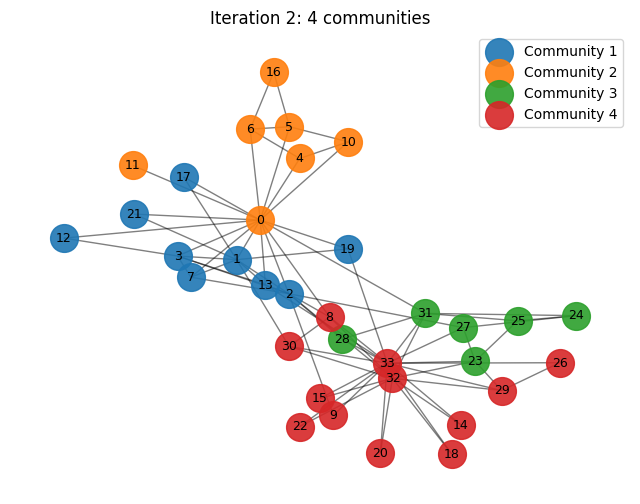

  Community size: 9, λ₁ = 2.020527
    → Split too unbalanced (2 vs 7), NOT splitting
  Community too small (7 nodes), keeping intact
  Community too small (6 nodes), keeping intact
  Community size: 12, λ₁ = 3.827423
    → Split too unbalanced (2 vs 10), NOT splitting

No more beneficial splits. Final: 4 communities


Detected 4 communities:
Community 1: [1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 2: [0, 4, 5, 6, 10, 11, 16]
Community 3: [23, 24, 25, 27, 28, 31]
Community 4: [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]

Tracking metrics evolution...

Plotting metrics evolution...


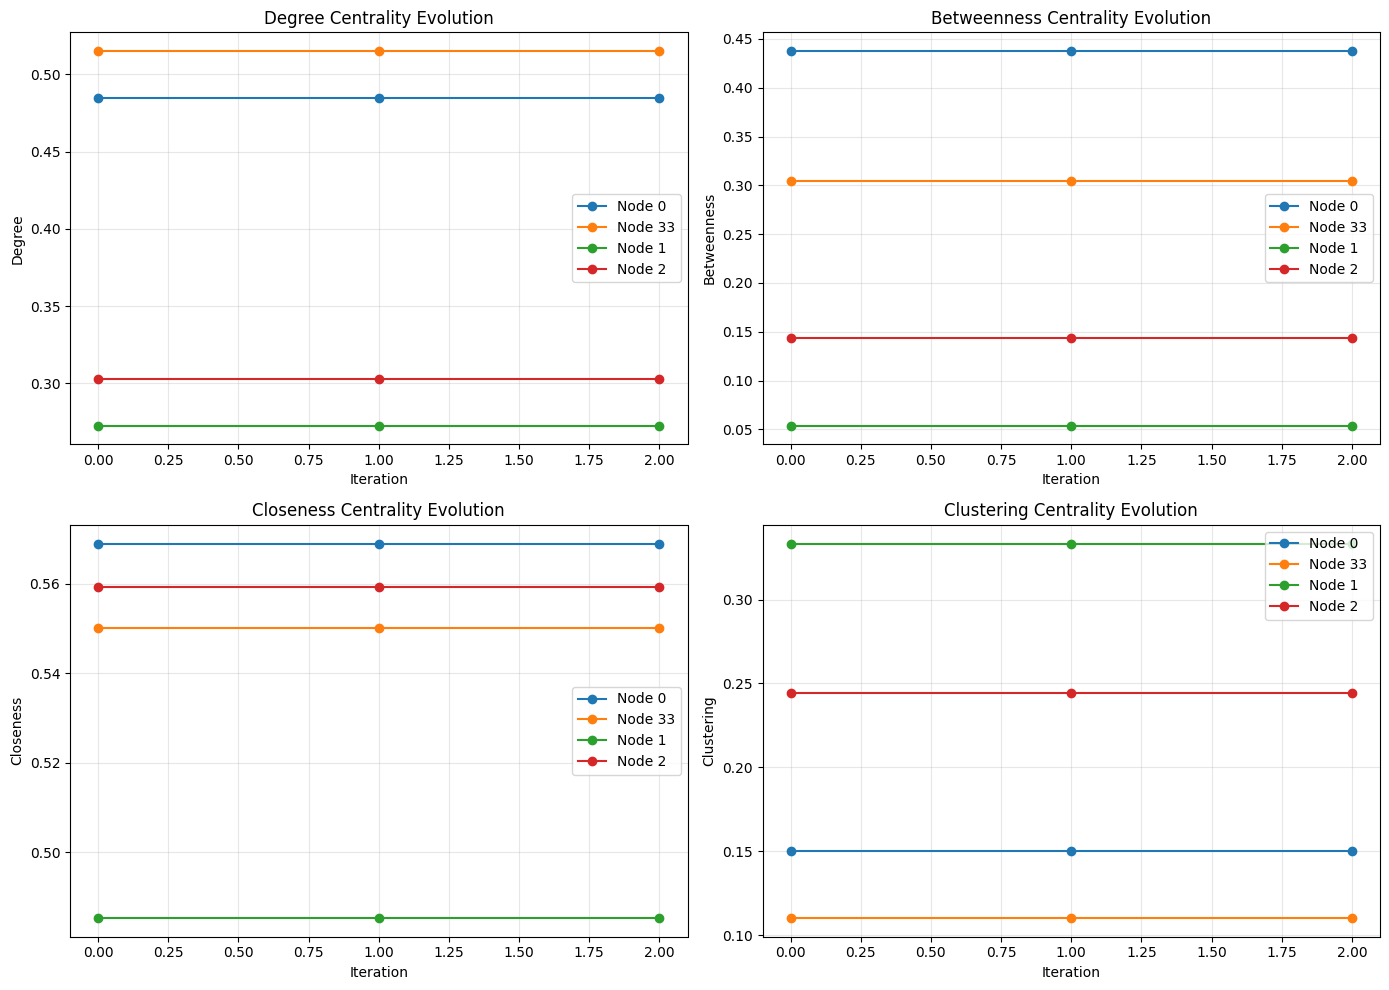

In [10]:
print("=" * 50)
print("Starting Recursive Spectral Modularity Analysis")
print("=" * 50)

# Detect communities
communities = recursive_spectral_modularity(G, pos=pos)

print(f"\nDetected {len(communities)} communities:")
for i, c in enumerate(communities, 1):
    print(f"Community {i}: {c}")


print("\nTracking metrics evolution...")
metrics_evolution = track_metrics_evolution(G, pos=pos, min_community_size=8)

print("\nPlotting metrics evolution...")
plot_metrics_evolution(metrics_evolution)


***Discussion about the nodes***

Across the recursive splits of the Karate Club network, a few nodes — particularly nodes 0, 1, 33, and 34 — consistently remain central. These nodes retain high values in degree, betweenness, and closeness centrality, even as the graph divides into smaller communities. Their persistence as central nodes reflects their structural roles as connectors or leaders within the network (corresponding to the instructor and the club president in the original dataset).

As modularity partitioning progresses, the community structure increasingly localizes interactions, reducing the relative importance of nodes with cross-community links. Within individual communities, nodes central to that subgroup (e.g., nodes 2, 3, or 32) may rise in local centrality measures, while global metrics like betweenness may drop for peripheral nodes. Thus, the evolution of centrality highlights how modularization shifts network influence from globally central “bridge” nodes to locally central “core” nodes within each community.

The recursive spectral modularity approach effectively reveals how influence and connectivity evolve within the Karate Club network. Initially, a few key nodes dominate the centrality landscape, acting as bridges across the entire graph. However, as the network divides into more cohesive communities, centrality becomes distributed among local leaders within each subgroup. This progression highlights the strong interplay between community structure and node importance, demonstrating that centrality is not fixed but context-dependent—shifting from global connectors to community-specific influencers as modular organization increases.